# E1 · Limpieza y preparación de datos
**Observatorio Antojo Colima** · Avlix Eduardo Jiménez Cuevas · Ingeniería de Datos

Este cuaderno justifica, con los datos reales del repositorio, cada decisión de limpieza que aplica el pipeline (`pipeline/plata.py` y `pipeline/oro.py`):

1. Valores faltantes: qué mecanismo los produce (MCAR, MAR o MNAR) y cómo se imputan.
2. Valores atípicos: cómo se detectan y por qué se **marcan** en lugar de borrarse.
3. Normalización (min-max contra z-score), discretización y jerarquías conceptuales.
4. Reducción de datos: de numerosidad (diario → mensual) y de dimensionalidad (8 insumos → 1 índice).

Para correrlo: desde la raíz del repositorio, `python -m pipeline.ejecutar` y luego abrir este cuaderno (`docs/E1/limpieza.ipynb`). Las reglas que aquí se justifican viven como scripts en `pipeline/` (el equivalente a `src/`) y corren solas en cada captura.

In [1]:
import sys
from pathlib import Path

RAIZ = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / "pyproject.toml").exists())
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from pipeline.plata import leer_bronce

DATA = RAIZ / "data"
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update(
    {"figure.figsize": (10, 3.6), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25}
)
pd.set_option("display.width", 140)

bronce = leer_bronce("sniim", DATA / "bronce")
plata = pd.read_csv(DATA / "plata" / "sniim_precios.csv", parse_dates=["fecha"])
cuarentena = pd.read_csv(DATA / "cuarentena" / "sniim_cuarentena.csv")
mensual = pd.read_csv(DATA / "oro" / "precios_mensuales.csv")
print(f"bronce: {len(bronce):,} registros · plata: {len(plata):,} · cuarentena: {len(cuarentena)}")
print(f"periodo: {plata['fecha'].min():%Y-%m-%d} a {plata['fecha'].max():%Y-%m-%d} · insumos: {plata['insumo'].nunique()}")

bronce: 5,253 registros · plata: 5,138 · cuarentena: 3
periodo: 2020-01-03 a 2026-11-13 · insumos: 8


## 1. Valores faltantes

En esta fuente hay dos tipos de faltante:

* **Faltante de celda**: un registro publicado sin precio. La puerta de calidad lo manda a cuarentena con el motivo *precio faltante*.
* **Faltante de periodo**: un mes en el que el SNIIM no publicó nada para un insumo. No hay fila que rechazar: el hueco aparece al pasar de diario a mensual, y es el que afecta al pronóstico.

In [2]:
celdas = bronce[["fecha", "precio_min", "precio_max", "precio_frec"]].replace("", np.nan).isna().sum()
print("Celdas vacías en bronce:")
print(celdas.to_string())

# NaN en la tabla = el insumo todavía no tenía serie (el limón empieza en 2020-04): no es un faltante
tabla = mensual.pivot(index="mes", columns="insumo", values="imputado").astype("boolean").fillna(False).astype(bool)
faltan = tabla[tabla.any(axis=1)]
print(f"\nMeses-insumo sin publicación: {int(mensual['imputado'].sum())} de {len(mensual)} ({mensual['imputado'].mean():.1%})")
faltan.replace({True: "FALTA", False: ""})

Celdas vacías en bronce:
fecha          0
precio_min     0
precio_max     0
precio_frec    0

Meses-insumo sin publicación: 37 de 661 (5.6%)


insumo,aguacate,cebolla,chile_jalapeno,chile_serrano,limon,papa,tomate_saladette,tomate_verde
mes,,,,,,,,
2020-05,,FALTA,,,,,,
2020-06,FALTA,FALTA,FALTA,FALTA,FALTA,FALTA,FALTA,FALTA
2020-07,FALTA,FALTA,FALTA,FALTA,FALTA,FALTA,FALTA,FALTA
2020-08,FALTA,FALTA,FALTA,FALTA,FALTA,FALTA,FALTA,FALTA
2020-09,,FALTA,,,,,,
2020-10,,FALTA,,,,,,
2020-11,,FALTA,,,,,,
2021-12,,FALTA,,,,,,
2022-01,,FALTA,,,,,,


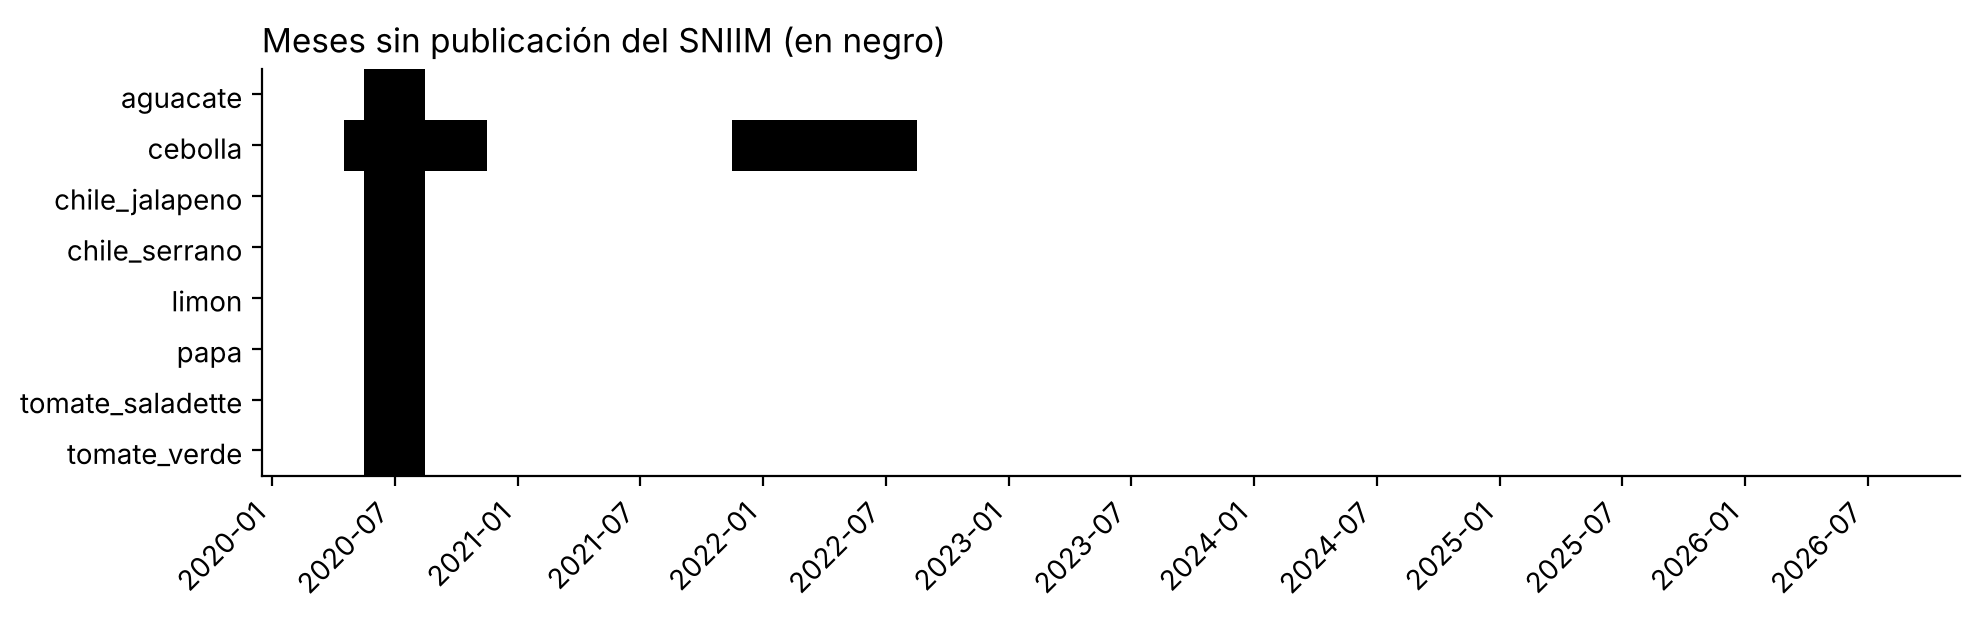

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.imshow(tabla.T.values, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(tabla.columns)), tabla.columns)
pos = range(0, len(tabla), 6)
ax.set_xticks(list(pos), [tabla.index[i] for i in pos], rotation=45, ha="right")
ax.set_title("Meses sin publicación del SNIIM (en negro)", loc="left")
ax.grid(False)
plt.tight_layout()
plt.show()

### ¿Qué mecanismo produce los faltantes?

Se ven **dos patrones distintos**:

* **Junio a agosto de 2020: faltan los 8 insumos a la vez.** El hueco depende solo de la fecha (el SNIIM dejó de publicar en Colima durante la pandemia), no del precio de ningún producto. Respecto al precio es **MCAR**; respecto al calendario es **MAR**, porque la fecha, que sí observamos, explica la ausencia.
* **Cebolla, de mayo a noviembre de 2020 y de diciembre de 2021 a agosto de 2022.** Solo falta la cebolla. Si el SNIIM dejó de reportarla *porque* su precio o su abasto cambiaron (por ejemplo, porque dejó de llegar cebolla de esa calidad), el faltante dependería del valor no observado: sería **MNAR**.

(El limón empieza en abril de 2020: los meses anteriores no son faltantes, la serie todavía no existía.)

Para distinguir MAR de MNAR comparamos el precio de la cebolla justo **antes y después** de cada hueco contra su comportamiento normal. Si los huecos coincidieran con precios extremos, sería señal de MNAR.

In [4]:
cebolla = mensual[mensual["insumo"] == "cebolla"].reset_index(drop=True)
cebolla["borde"] = cebolla["imputado"].shift(1, fill_value=False) | cebolla["imputado"].shift(-1, fill_value=False)
obs = cebolla[~cebolla["imputado"]]
borde, resto = obs[obs["borde"]]["precio_mediana"], obs[~obs["borde"]]["precio_mediana"]
mediana_movil = obs.set_index("mes")["precio_mediana"].rolling(12, min_periods=4, center=True).median()
desvio = (obs.set_index("mes")["precio_mediana"] / mediana_movil - 1) * 100
print("Precio de la cebolla en los meses junto a un hueco:")
print(obs[obs["borde"]][["mes", "precio_mediana"]].to_string(index=False))
print(
    "\nDesvío contra su mediana móvil de 12 meses, meses junto a un hueco:",
    desvio[obs[obs["borde"]]["mes"]].round(1).tolist(),
    "%",
)
u = stats.mannwhitneyu(desvio[obs[obs["borde"]]["mes"]].dropna(), desvio[obs[~obs["borde"]]["mes"]].dropna())
print(f"Mann-Whitney (desvío junto a huecos contra el resto): p = {u.pvalue:.3f}")

Precio de la cebolla en los meses junto a un hueco:
    mes  precio_mediana
2020-04            14.0
2020-12            15.5
2021-11            25.0
2022-09            34.0

Desvío contra su mediana móvil de 12 meses, meses junto a un hueco: [-6.7, 6.9, 51.5, 106.1] %


Mann-Whitney (desvío junto a huecos contra el resto): p = 0.155


**Lectura.** La prueba no es significativa (p ≈ 0.15), pero solo hay 4 meses de borde y la prueba casi no tiene potencia. Los números dicen más que el valor p:

* En el **hueco de 2020** los bordes son normales (−7 % y +7 % contra su mediana móvil): coincide con el hueco general de la pandemia, así que lo tratamos como **MAR** (lo explica la fecha).
* En el **hueco largo de 2021–2022** la cebolla desaparece cuando está **51 % arriba** de lo normal y reaparece **106 % arriba**. El hueco ocurre en plena alza de precio, así que lo más probable es que sea **MNAR**: el dato falta justo cuando la cebolla era escasa y cara.

**Consecuencia.** En un hueco MNAR, interpolar entre los dos bordes probablemente **subestima** el precio real a la mitad del hueco (si hubo un pico, la recta no lo ve). No hay forma de recuperar ese valor desde esta fuente, así que: (1) los meses quedan marcados como imputados en `precios_mensuales` y en `insumos_imputados` del índice, (2) el pronóstico se valida con los últimos 12 meses, que están completos, y (3) queda como riesgo documentado en el plan SQA.

### ¿Con qué método imputar?

Hicimos un experimento: ocultamos meses que **sí** conocemos, los rellenamos con cada método y medimos el error. Gana el método que mejor reconstruye lo que ya sabíamos.

In [5]:
def imputar(serie, metodo):
    if metodo == "arrastre (último valor)":
        return serie.ffill()
    if metodo == "media del insumo":
        return serie.fillna(serie.mean())
    if metodo == "interpolación lineal":
        return serie.interpolate(method="time")
    if metodo == "interpolación spline":
        return serie.interpolate(method="spline", order=2)


rng = np.random.default_rng(2026)
metodos = ["arrastre (último valor)", "media del insumo", "interpolación lineal", "interpolación spline"]
resultados = []
for insumo, g in mensual[~mensual["imputado"]].groupby("insumo"):
    s = pd.Series(g["precio_mediana"].values, index=pd.PeriodIndex(g["mes"], freq="M").to_timestamp()).asfreq("MS")
    candidatos = np.where(s.notna().values)[0][3:-3]
    for _ in range(30):
        for largo in (1, 3):
            ini = rng.choice(candidatos[:-largo])
            oculto = s.copy()
            idx = s.index[ini : ini + largo]
            if s[idx].isna().any():
                continue
            oculto[idx] = np.nan
            for m in metodos:
                err = (imputar(oculto, m)[idx] - s[idx]).abs().mean() / s[idx].mean() * 100
                resultados.append({"insumo": insumo, "hueco_meses": largo, "metodo": m, "error_pct": err})
exp = pd.DataFrame(resultados)
resumen = exp.pivot_table(index="metodo", columns="hueco_meses", values="error_pct", aggfunc="mean").round(1)
resumen.columns = [f"error % hueco de {c} mes(es)" for c in resumen.columns]
resumen.sort_values(resumen.columns[-1])

,error % hueco de 1 mes(es),error % hueco de 3 mes(es)
metodo,,
interpolación lineal,10.1,15.2
arrastre (último valor),13.2,21.0
media del insumo,23.7,23.2
interpolación spline,15.3,28.4


**Decisión.** Gana la **interpolación lineal en el tiempo**, que es la que aplica `pipeline/oro.py`: usa el mes anterior y el siguiente, respeta la tendencia y no inventa curvaturas como la spline. La media del insumo es la peor porque borra la inflación de 6 años. Además:

* Nunca se rellena antes del primer dato ni después del último (no se extrapola).
* Cada valor imputado queda marcado (`imputado`, `metodo`), y el índice lista en `insumos_imputados` qué insumos se rellenaron ese mes.
* **Limitación**: el hueco de 9 meses de la cebolla es mucho mayor que los probados y además es probablemente MNAR; ahí la interpolación es solo una recta entre dos precios altos.

## 2. Valores atípicos

Comparamos tres reglas sobre el precio frecuente diario:

* **IQR global**: fuera de Q1 − 1.5·IQR o Q3 + 1.5·IQR de toda la serie del insumo.
* **z clásico global**: |z| > 3 con media y desviación de toda la serie.
* **z robusto móvil** (la que usa el pipeline): mediana y MAD de los 120 días anteriores, con |z| > 3.5. Si la MAD es 0 se usa la desviación absoluta media (defecto 16 de Carol).

In [6]:
def iqr_global(s):
    q1, q3 = s.quantile([0.25, 0.75])
    r = q3 - q1
    return (s < q1 - 1.5 * r) | (s > q3 + 1.5 * r)


filas = []
for insumo, g in plata.groupby("insumo"):
    s = g["precio_frec"]
    z = (s - s.mean()) / s.std()
    filas.append(
        {
            "insumo": insumo,
            "IQR global": int(iqr_global(s).sum()),
            "z clásico |z|>3": int((z.abs() > 3).sum()),
            "z robusto móvil": int(g["atipico"].sum()),
            "registros": len(g),
        }
    )
comp = pd.DataFrame(filas).set_index("insumo")
comp.loc["TOTAL"] = comp.sum()
comp

,IQR global,z clásico |z|>3,z robusto móvil,registros
insumo,,,,
aguacate,15,15,22,659
cebolla,28,9,37,545
chile_jalapeno,9,5,33,661
chile_serrano,56,7,87,661
limon,20,8,25,631
papa,0,0,47,661
tomate_saladette,68,0,37,659
tomate_verde,18,4,10,661
TOTAL,214,48,298,5138


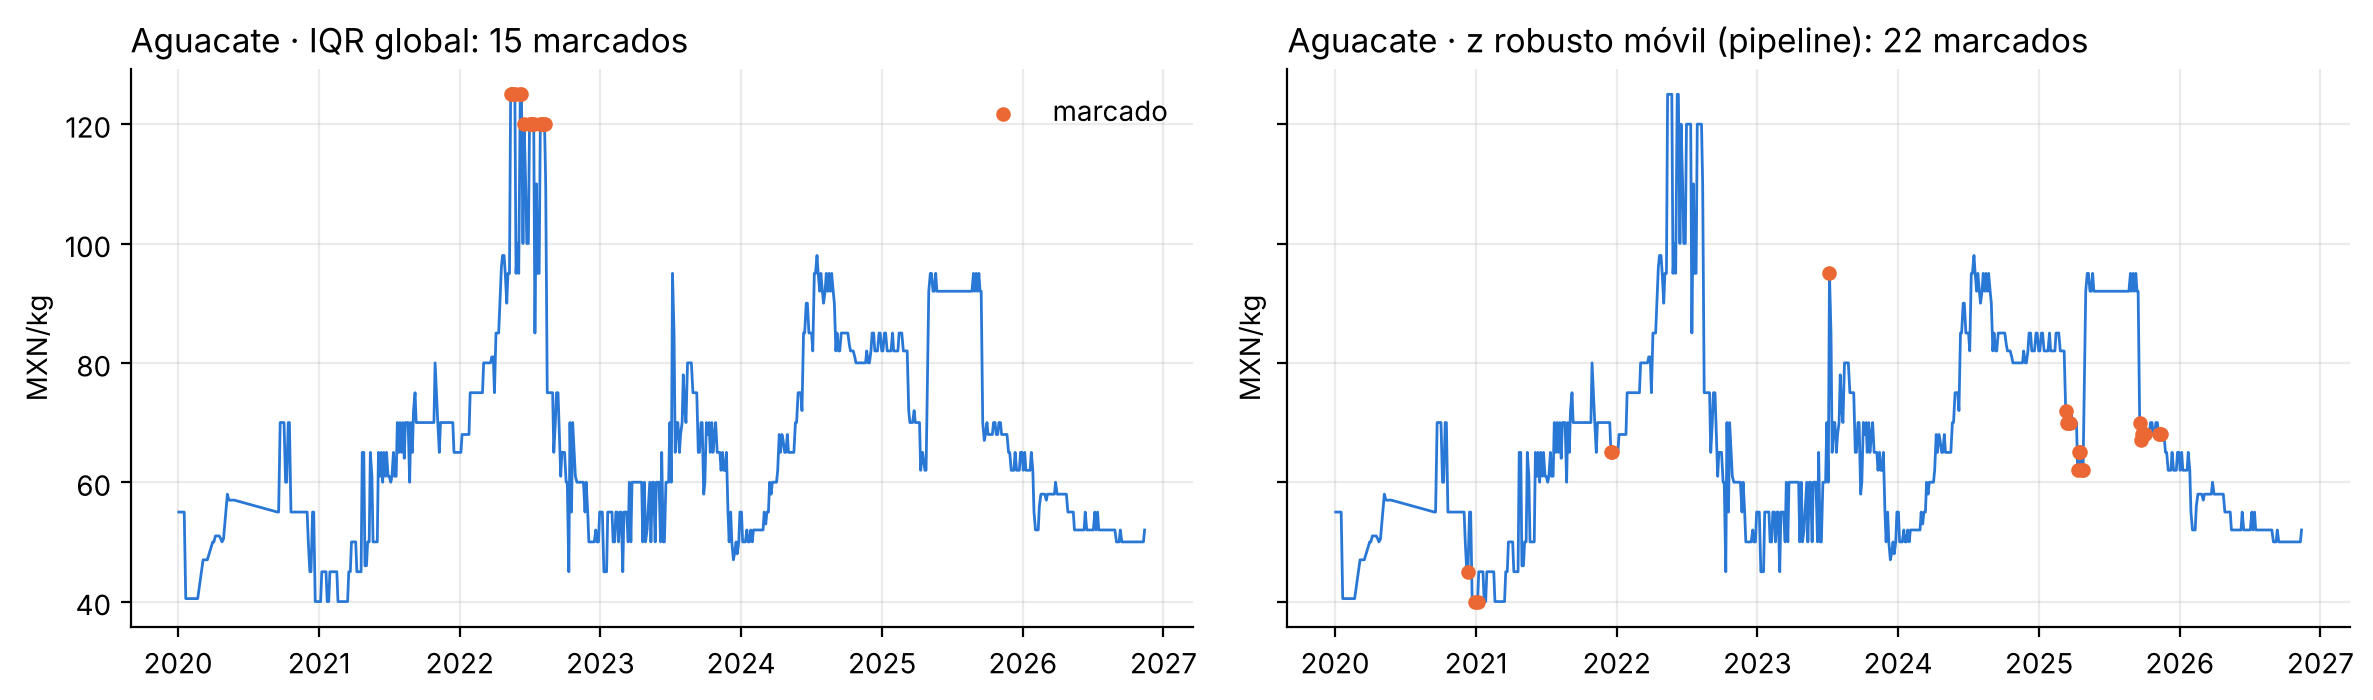

In [7]:
g = plata[plata["insumo"] == "aguacate"].sort_values("fecha")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (titulo, marca) in zip(
    axes, [("IQR global", iqr_global(g["precio_frec"])), ("z robusto móvil (pipeline)", g["atipico"])], strict=True
):
    ax.plot(g["fecha"], g["precio_frec"], color=AZUL, lw=1)
    ax.scatter(g.loc[marca, "fecha"], g.loc[marca, "precio_frec"], color=NARANJA, s=18, zorder=3, label="marcado")
    ax.set_title(f"Aguacate · {titulo}: {int(marca.sum())} marcados", loc="left")
    ax.set_ylabel("MXN/kg")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

**Lectura.**

* El **IQR global** marca en el aguacate solo la temporada alta de 2022 completa: semanas seguidas a $120/kg. Eso no es un dato raro, es un **periodo** (escasez real), y en la papa no marca nada. En el tomate saladette marca 67 días, mientras que el z clásico marca 0: las dos reglas globales no se ponen de acuerdo porque dependen de la forma de toda la serie.
* El **z robusto móvil** compara cada precio contra lo normal de los 120 días anteriores, así que marca los **saltos bruscos** (por ejemplo, los cambios de nivel del aguacate en 2025) y no la inflación ni las temporadas largas.
* **Limitación del z robusto**: cuando el precio casi no se mueve (papa), cualquier cambio pequeño queda marcado (47 días). Por eso solo se marca y nunca se borra.

**Decisión: marcar, no borrar.** En este dominio un atípico casi siempre es **real**: el día que el limón se dispara es justo el que le importa al taquero. Por eso:

* El pipeline agrega `z_robusto` y `atipico` y conserva el registro.
* La reducción a mensual usa la **mediana**, que es robusta: quitar los atípicos cambia la mediana mensual solo 0.7 % en promedio (abajo).
* Solo va a cuarentena lo que es **imposible**, no lo raro: precio fuera de $1–$300/kg o mínimo > máximo (3 registros, ver abajo).

In [8]:
print("Registros en cuarentena (imposibles, no solo raros):")
cuarentena[["motivo", "fecha", "producto_sniim", "precio_min", "precio_frec", "precio_max"]]

Registros en cuarentena (imposibles, no solo raros):


,motivo,fecha,producto_sniim,precio_min,precio_frec,precio_max
0,regla de negocio: debe cumplirse mínimo <= fre...,2021-03-16,Tomate Saladette - Primera,10.0,11.0,10.0
1,regla de negocio: debe cumplirse mínimo <= fre...,2020-03-24,Cebolla Bola - Primera,12.0,12.0,10.0
2,regla de negocio: debe cumplirse mínimo <= fre...,2020-03-24,Aguacate Hass - Primera,50.0,50.0,45.0


In [9]:
# ¿Cuánto cambia el mes si quitáramos los atípicos? Si casi nada, la mediana ya los absorbe.
plata["mes"] = plata["fecha"].dt.to_period("M").astype(str)
con = plata.groupby(["insumo", "mes"])["precio_frec"].median()
sin = plata[~plata["atipico"]].groupby(["insumo", "mes"])["precio_frec"].median()
dif = ((sin - con).abs() / con * 100).dropna()
print(
    f"Diferencia en la mediana mensual al quitar atípicos: promedio {dif.mean():.2f} %, percentil 95 {dif.quantile(0.95):.2f} %"
)

Diferencia en la mediana mensual al quitar atípicos: promedio 0.72 %, percentil 95 2.63 %


### Atípico contra ruido

* Un **atípico** es un valor que se sale del comportamiento normal: un salto brusco por helada o escasez, o un error de captura. Se detecta registro por registro (arriba) y se decide caso por caso: a cuarentena si es imposible, marcado si es raro pero posible.
* El **ruido** es la variación pequeña y aleatoria alrededor del nivel real: el precio sube o baja unos pesos entre una publicación y otra sin que haya cambiado nada de fondo. No se detecta registro por registro, porque cada punto por separado parece normal. Se **reduce** promediando.

Medimos el ruido como la variación del precio **dentro de cada mes** (coeficiente de variación) y la comparamos con el cambio **entre meses**, que es la señal que nos interesa:

In [10]:
ruido = pd.DataFrame(
    {
        "ruido dentro del mes (CV %)": plata.groupby(["insumo", "mes"])["precio_frec"]
        .agg(lambda s: s.std() / s.mean() * 100 if len(s) > 2 else np.nan)
        .groupby("insumo")
        .median(),
        "cambio típico entre meses (%)": plata.groupby(["insumo", "mes"])["precio_frec"]
        .median()
        .groupby("insumo")
        .apply(lambda s: (s.pct_change().abs() * 100).median()),
    }
).round(1)
sin_cambio = (plata.sort_values("fecha").groupby("insumo")["precio_frec"].diff() == 0).mean()
print(f"Publicaciones consecutivas con el mismo precio: {sin_cambio:.0%}")
ruido

Publicaciones consecutivas con el mismo precio: 58%


,ruido dentro del mes (CV %),cambio típico entre meses (%)
insumo,,
aguacate,4.5,6.9
cebolla,7.6,9.5
chile_jalapeno,6.5,4.8
chile_serrano,8.8,9.1
limon,6.0,8.0
papa,3.7,3.1
tomate_saladette,7.8,12.0
tomate_verde,8.3,9.1


**Lectura y decisión sobre el ruido.** Dentro de un mismo mes el precio varía entre 4 % (papa) y 9 % (chile serrano) sin que cambie su nivel, y más de la mitad de las publicaciones consecutivas repiten el precio anterior. Ese vaivén es ruido. El tratamiento es **suavizar, no borrar**: la capa oro usa la **mediana mensual**, que absorbe el ruido y además es robusta a los atípicos. Así, el cambio entre meses (la señal) se compara contra un nivel estable y no contra un día suelto. En 6 de los 8 insumos la señal es mayor que el ruido; en la **papa** (3.1 % contra 3.7 %) y el **chile jalapeño** (4.8 % contra 6.5 %) son parecidos, así que un cambio de un solo mes en esos dos insumos se debe leer con cautela. No se aplica un suavizado más fuerte (por ejemplo, una media móvil de varios meses) porque borraría los picos reales de escasez que le importan al taquero.

## 3. Normalización, discretización y jerarquías

### Min-max contra z-score

Los 8 insumos están en escalas distintas: el aguacate cuesta ~4 veces lo que la papa. Para compararlos o combinarlos hay que normalizarlos.

In [11]:
precios = mensual.pivot(index="mes", columns="insumo", values="precio_mediana").dropna()
minmax = (precios - precios.min()) / (precios.max() - precios.min())
zscore = (precios - precios.mean()) / precios.std()
pd.DataFrame(
    {
        "rango original": precios.max() - precios.min(),
        "media": precios.mean(),
        "min-max: rango": minmax.max() - minmax.min(),
        "z-score: desviación": zscore.std(),
        "z-score: máximo": zscore.max(),
    }
).round(2)

,rango original,media,min-max: rango,z-score: desviación,z-score: máximo
insumo,,,,,
aguacate,80.0,66.85,1.0,1.0,3.30
cebolla,31.0,19.86,1.0,1.0,3.06
chile_jalapeno,32.5,30.83,1.0,1.0,2.83
chile_serrano,61.0,37.99,1.0,1.0,3.25
limon,44.0,30.79,1.0,1.0,3.31
papa,23.0,25.58,1.0,1.0,1.64
tomate_saladette,28.5,23.46,1.0,1.0,2.74
tomate_verde,27.0,22.33,1.0,1.0,2.68


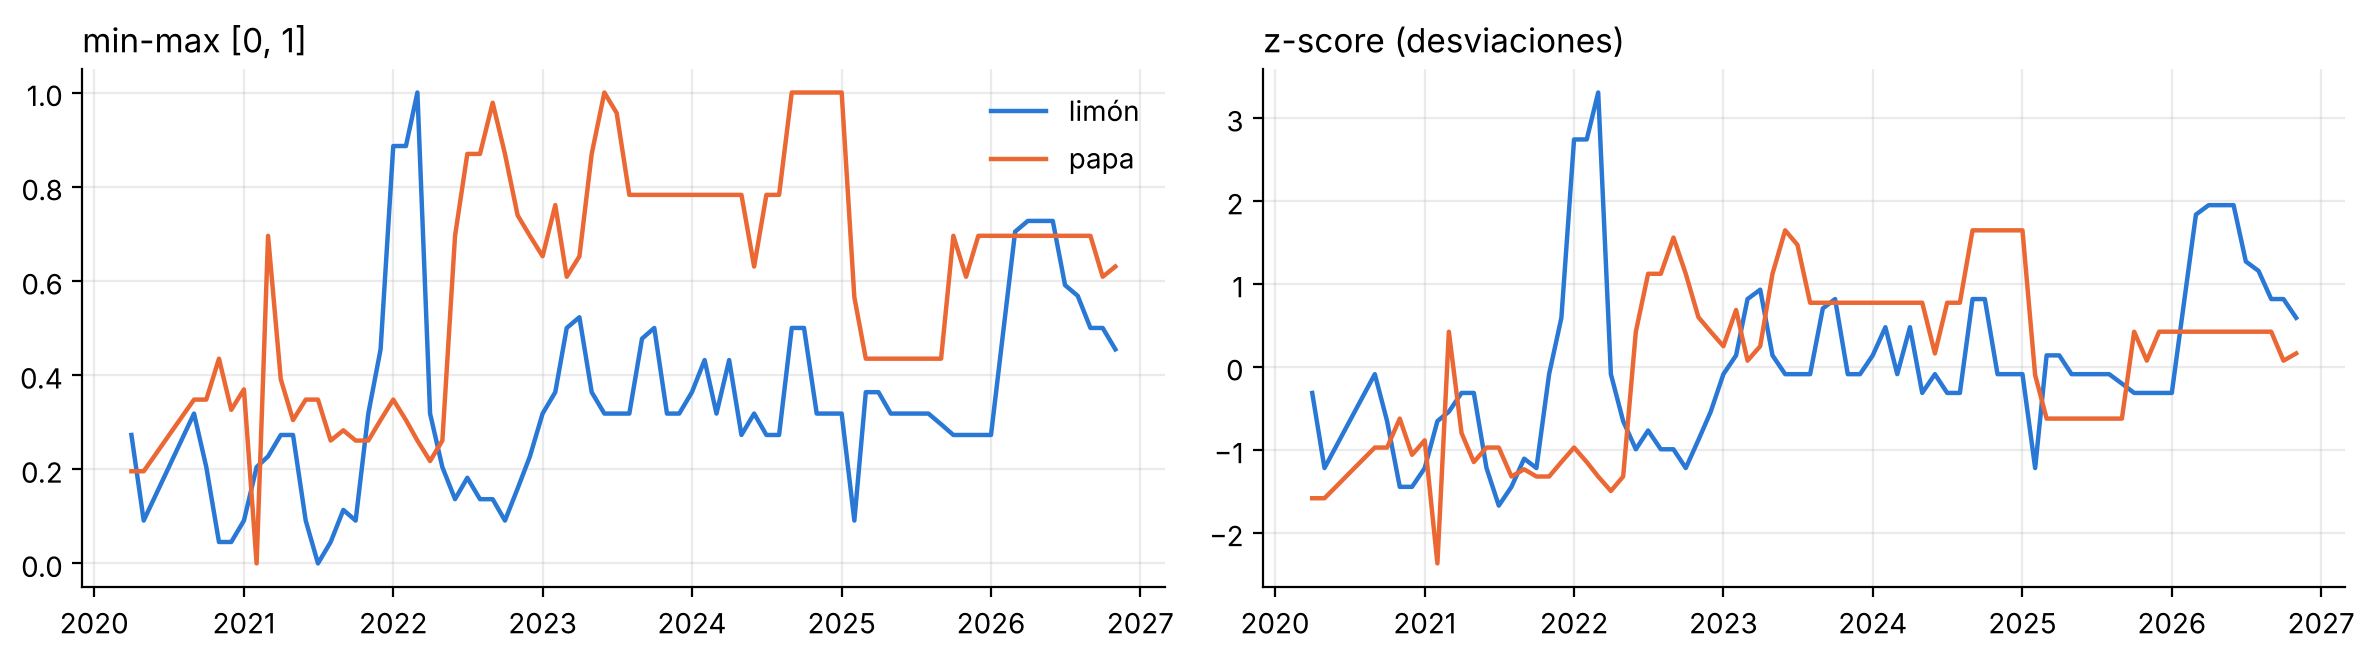

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharex=True)
for ax, (t, d) in zip(axes, [("min-max [0, 1]", minmax), ("z-score (desviaciones)", zscore)], strict=True):
    ax.plot(pd.PeriodIndex(d.index, freq="M").to_timestamp(), d["limon"], color=AZUL, lw=1.6, label="limón")
    ax.plot(pd.PeriodIndex(d.index, freq="M").to_timestamp(), d["papa"], color=NARANJA, lw=1.6, label="papa")
    ax.set_title(t, loc="left")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

**Decisión.**

| Uso | Método | Por qué |
|---|---|---|
| Semáforo del tablero y mapas de calor | **min-max** | Queda en [0, 1], fácil de leer ("qué tan cerca está del máximo histórico"). Es sensible a un solo extremo, pero aquí los extremos son reales |
| PCA de E3 y comparación entre insumos | **z-score** | No acota el rango y pondera igual la variabilidad de cada insumo, que es lo que pide el PCA |
| Índice de Costo del Taco | **relativo a una base** (2021 = 100) | Se interpreta en porcentaje ("la canasta cuesta 10 % más que en 2021"), que es el lenguaje del taquero |

### Discretización: semáforo de precio

Al taquero no le sirve "z = 1.3"; le sirve *barato / normal / caro*. Comparamos dos cortes del precio de cada insumo en los últimos 24 meses:

In [13]:
recientes = precios.iloc[-24:]
igual_ancho = recientes.apply(lambda s: pd.cut(s, 3, labels=["barato", "normal", "caro"]))
igual_frec = recientes.apply(lambda s: pd.qcut(s, 3, labels=["barato", "normal", "caro"]))
conteo = pd.DataFrame(
    {"igual ancho": igual_ancho.stack().value_counts(), "igual frecuencia (terciles)": igual_frec.stack().value_counts()}
)
conteo

,igual ancho,igual frecuencia (terciles)
barato,84,91
normal,64,53
caro,44,48


In [14]:
ultimo = precios.index[-1]
semaforo = pd.DataFrame(
    {"precio": precios.loc[ultimo], "terciles": igual_frec.loc[ultimo], "igual ancho": igual_ancho.loc[ultimo]}
)
print(f"Semáforo del mes {ultimo} (mes en curso: se actualiza con cada captura)")
semaforo

Semáforo del mes 2026-11 (mes en curso: se actualiza con cada captura)


,precio,terciles,igual ancho
insumo,,,
aguacate,50.0,barato,barato
cebolla,23.5,caro,caro
chile_jalapeno,32.0,barato,normal
chile_serrano,26.5,barato,barato
limon,36.0,normal,normal
papa,26.5,normal,normal
tomate_saladette,19.0,barato,barato
tomate_verde,22.0,barato,barato


**Decisión: terciles (igual frecuencia).** Con igual ancho, un mes extremo estira los cortes y casi todo cae en "barato"; con terciles cada categoría tiene el mismo número de meses, así que "caro" significa *uno de los 8 meses más caros de los últimos 2 años*, y eso se puede explicar.

### Jerarquías conceptuales

Para agregar a distintos niveles, el pipeline define dos jerarquías (en `pipeline/catalogos.py` y en las dimensiones de oro):

In [15]:
dim_insumo = pd.read_csv(DATA / "oro" / "dim_insumo.csv")
dim_mun = pd.read_csv(DATA / "oro" / "dim_municipio.csv", dtype={"municipio_clave": str})
print("producto SNIIM → insumo → tipo → canasta")
display(dim_insumo)
print("municipio → estado (y lo que aporta cada fuente)")
display(dim_mun)

producto SNIIM → insumo → tipo → canasta


,insumo,tipo,canasta,producto_sniim
0,chile_jalapeno,chile,taquera,Chile Jalapeño - Primera
1,chile_serrano,chile,taquera,Chile Serrano - Primera
2,aguacate,fruta,taquera,Aguacate Hass - Primera
3,limon,fruta,taquera,Limón c/semilla # 5 - Primera
4,cebolla,verdura,taquera,Cebolla Bola - Primera
5,papa,verdura,taquera,Papa Alpha - Primera
6,tomate_saladette,verdura,taquera,Tomate Saladette - Primera
7,tomate_verde,verdura,taquera,Tomate Verde - Primera


municipio → estado (y lo que aporta cada fuente)


,municipio_clave,municipio,estado,negocios_denue,mercado_sniim
0,06001,Armería,Colima,358,False
1,06002,Colima,Colima,1833,True
2,06003,Comala,Colima,180,False
3,06004,Coquimatlán,Colima,168,False
4,06005,Cuauhtémoc,Colima,268,False
5,06006,Ixtlahuacán,Colima,67,False
6,06007,Manzanillo,Colima,1715,False
7,06008,Minatitlán,Colima,92,False
8,06009,Tecomán,Colima,1412,False
9,06010,Villa de Álvarez,Colima,1304,False


In [16]:
por_tipo = mensual.groupby(["mes", "tipo"])["precio_mediana"].mean().unstack().iloc[-12:].round(1)
print("Ejemplo de roll-up: precio promedio por tipo de insumo, últimos 12 meses")
por_tipo

Ejemplo de roll-up: precio promedio por tipo de insumo, últimos 12 meses


tipo,chile,fruta,verdura
mes,,,
2025-12,53.0,45.0,25.0
2026-01,53.0,45.0,24.8
2026-02,32.0,47.5,24.5
2026-03,32.0,52.5,24.5
2026-04,32.8,53.0,29.8
2026-05,35.0,50.0,29.8
2026-06,32.0,50.0,29.2
2026-07,32.0,47.0,21.8
2026-08,32.0,46.5,19.8


## 4. Reducción de datos

### Numerosidad: de diario a mensual

In [17]:
print(f"Plata diaria: {len(plata):,} filas → oro mensual: {len(mensual):,} filas ({1 - len(mensual) / len(plata):.0%} menos)")
dias_por_mes = plata.groupby(["insumo", "mes"]).size()
print(
    f"Días con publicación por mes: mediana {dias_por_mes.median():.0f}, mínimo {dias_por_mes.min()}, máximo {dias_por_mes.max()}"
)

Plata diaria: 5,138 filas → oro mensual: 661 filas (87% menos)
Días con publicación por mes: mediana 9, mínimo 3, máximo 9


El SNIIM publica de forma irregular (martes y viernes, con huecos), así que la serie diaria no tiene frecuencia fija y no se puede modelar directamente con Holt-Winters o ARIMA. Pasar a **mediana mensual** da una serie regular y robusta a atípicos, y el horizonte mensual coincide con cómo decide el taquero (promociones del mes, ajuste de menú).

### Dimensionalidad: de 8 insumos a 1 índice

¿Se justifica resumir los 8 precios en un solo número? Lo comprobamos con la correlación y con un PCA sobre los precios estandarizados (z-score):

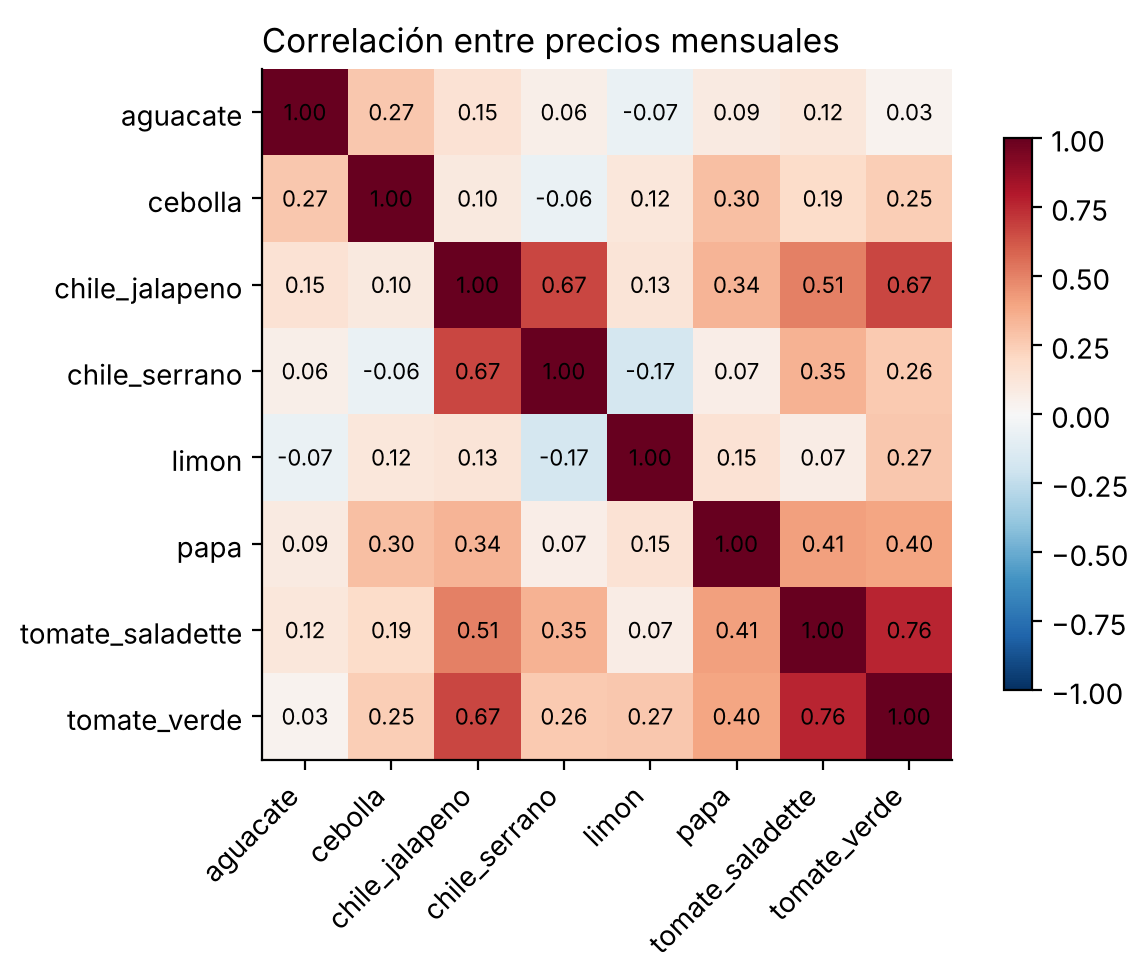

In [18]:
corr = precios.corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(8), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(8), corr.columns)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im, shrink=0.8)
ax.set_title("Correlación entre precios mensuales", loc="left")
plt.tight_layout()
plt.show()

In [19]:
valores, vectores = np.linalg.eigh(np.cov(zscore.T))
orden = np.argsort(valores)[::-1]
valores, vectores = valores[orden], vectores[:, orden]
varianza = valores / valores.sum()
pc1 = zscore.values @ vectores[:, 0]
indice = pd.read_csv(DATA / "oro" / "indice_costo_taco.csv").set_index("mes")["indice"].reindex(precios.index)
print("Varianza explicada:", " · ".join(f"PC{i + 1} {v:.0%}" for i, v in enumerate(varianza[:4])))
print("Cargas de PC1:", dict(zip(precios.columns, np.round(np.abs(vectores[:, 0]), 2), strict=True)))
print(f"Correlación entre PC1 y el Índice de Costo del Taco (pesos iguales): {abs(np.corrcoef(pc1, indice)[0, 1]):.2f}")

Varianza explicada: PC1 37% · PC2 18% · PC3 15% · PC4 10%
Cargas de PC1: {'aguacate': np.float64(0.12), 'cebolla': np.float64(0.2), 'chile_jalapeno': np.float64(0.49), 'chile_serrano': np.float64(0.32), 'limon': np.float64(0.12), 'papa': np.float64(0.34), 'tomate_saladette': np.float64(0.48), 'tomate_verde': np.float64(0.5)}
Correlación entre PC1 y el Índice de Costo del Taco (pesos iguales): 0.95


**Lectura y decisión.**

* **PC1 explica solo el 37 %** de la variación: los insumos no se mueven todos juntos. Los tomates, el chile jalapeño y la papa cargan fuerte en PC1; el **aguacate y el limón casi no** (0.12): tienen su propia dinámica de temporada.
* Aun así, el índice de **pesos iguales** tiene una correlación de **0.95** con PC1: reducir a un índice conserva la señal común, que es la que le interesa al taquero ("¿mi canasta está cara este mes?").
* Preferimos pesos iguales a las cargas de PCA porque se explica en una frase y no cambia cada vez que entra un dato nuevo. Lo que se pierde (aguacate y limón) se compensa con la pestaña "Insumos" del tablero, y el PCA completo se hará en E3.

## 5. Resumen de decisiones

| Problema | Decisión | Dónde se aplica | Evidencia en este cuaderno |
|---|---|---|---|
| Registro imposible (mín > máx, fuera de rango, sin precio) | Cuarentena con motivo | `pipeline/esquemas.py`, `plata.py` | Sección 2 |
| Duplicados entre capturas traslapadas | Se conserva la última captura; si el precio difiere, cuarentena | `plata.py` | Reporte de la puerta |
| Mes sin publicación | Interpolación lineal en el tiempo, marcada | `oro.py` | Experimento de la sección 1 |
| Atípico | Se marca con z robusto móvil; no se borra | `plata.py` | Sección 2 |
| Escalas distintas | z-score para análisis, min-max para semáforo, base 2021 para el índice | `oro.py`, tablero | Sección 3 |
| Comunicación al taquero | Terciles: barato / normal / caro | tablero | Sección 3 |
| Frecuencia irregular | Mediana mensual | `oro.py` | Sección 4 |
| 8 series | Índice de pesos iguales (correlación 0.95 con PC1) | `oro.py` | Sección 4 |
| Hueco largo de la cebolla (probable MNAR) | Se imputa, se marca y se declara como riesgo | `oro.py`, plan SQA | Sección 1 |